# 02. Prompt별 요약 결과 분석

Clothing 데이터에서 Segment, Reasoning, Aspect Summary Prompt의 출력을 비교합니다.
세 데이터의 행 정렬, 출력 길이, 속성 보존과 추천 성능을 같은 기준으로 확인합니다.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 데이터 처리 및 시각화
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 비교 표의 모든 열과 전체 문장 표시
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

sns.set_theme(
    style='white',
    context='notebook',
    font_scale=1.05,
    rc={
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'savefig.facecolor': 'white'
    }
)


## Utils

In [4]:
# 저장된 파일명 중 실제로 존재하는 파일 선택
def find_prompt_file(file_names):
    for file_name in file_names:
        file_path = data_dir / file_name

        if file_path.exists():
            return file_path

    raise FileNotFoundError(
        f'Prompt 데이터 파일을 찾지 못했습니다: {file_names}'
    )

## Load Dataset

In [5]:
# Prompt별 저장 파일 위치
data_dir = Path(
    '/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed'
)

prompt_file_candidates = {
    'Aspect summary': [
        'Clothing_Shoes_v6_final.pkl',
        'Clothing_Shoes_aspect_final.pkl',
        'Clothing_Shoes_simple_v5_final.pkl'
    ],
    'Segment': [
        'Clothing_Shoes_segment_v5_final.pkl',
        'Clothing_Shoes_segment_final.pkl'
    ],
    'Reasoning': [
        'Clothing_Shoes_reasoning_v5_final.pkl',
        'Clothing_Shoes_reasoning_final.pkl'
    ]
}

In [6]:
prompt_data = {}
data_overview_rows = []

for strategy, file_names in prompt_file_candidates.items():
    file_path = find_prompt_file(file_names)
    frame = pd.read_pickle(file_path).reset_index(drop=True)
    prompt_data[strategy] = frame

    data_overview_rows.append({
        'prompt_strategy': strategy,
        'file_name': file_path.name,
        'row_count': len(frame),
        'llama_missing': frame['LLaMA_Output'].isna().sum(),
        'llava_missing': frame['LLaVA_Output'].isna().sum()
    })

# 세 파일이 같은 원문 행으로 구성됐는지 확인
reference_df = prompt_data['Aspect summary']
alignment_columns = ['user_id', 'asin', 'text', 'rating']

for row in data_overview_rows:
    strategy = row['prompt_strategy']
    frame = prompt_data[strategy]
    row['aligned_with_aspect'] = (
        len(frame) == len(reference_df)
        and frame[alignment_columns].equals(
            reference_df[alignment_columns]
        )
    )

data_overview_df = pd.DataFrame(data_overview_rows)
data_overview_df

,prompt_strategy,file_name,row_count,llama_missing,llava_missing,aligned_with_aspect
0,Aspect summary,Clothing_Shoes_v6_final.pkl,66718,0,0,True
1,Segment,Clothing_Shoes_segment_final.pkl,66718,0,0,True
2,Reasoning,Clothing_Shoes_reasoning_final.pkl,66718,0,0,True


## Prompt별 출력 길이

LLaMA 요약과 LLaVA 설명의 길이 및 원문 대비 압축 정도를 Prompt별로 비교합니다.


In [7]:
# Prompt와 출력 종류별 단어 수 집계
length_summary_rows = []

for strategy, frame in prompt_data.items():
    review_length = (
        frame['text'].fillna('').astype(str).str.split().str.len()
    )

    output_columns = {
        'Text summary': 'LLaMA_Output',
        'Image description': 'LLaVA_Output'
    }

    for output_type, column in output_columns.items():
        output_text = frame[column].fillna('').astype(str)
        output_length = output_text.str.split().str.len()
        valid_review = review_length.gt(0)

        compression_ratio = (
            output_length[valid_review]
            .div(review_length[valid_review])
        )

        length_summary_rows.append({
            'prompt_strategy': strategy,
            'output_type': output_type,
            'row_count': len(frame),
            'empty_count': output_text.str.strip().eq('').sum(),
            'mean_words': output_length.mean(),
            'median_words': output_length.median(),
            'p95_words': output_length.quantile(0.95),
            'mean_compression_ratio': compression_ratio.mean()
        })

length_summary_df = pd.DataFrame(length_summary_rows).round(3)
length_summary_df


,prompt_strategy,output_type,row_count,empty_count,mean_words,median_words,p95_words,mean_compression_ratio
0,Aspect summary,Text summary,66718,31,101.815,97.0,171.0,1.952
1,Aspect summary,Image description,66718,0,159.352,162.0,199.0,3.512
2,Segment,Text summary,66718,2,138.146,133.0,210.0,2.787
3,Segment,Image description,66718,0,150.819,147.0,198.0,3.337
4,Reasoning,Text summary,66718,0,207.198,208.0,222.0,4.494
5,Reasoning,Image description,66718,0,182.438,183.0,201.0,4.015


## 동일 리뷰의 Text Summary 비교

같은 리뷰에 대한 세 Prompt의 LLaMA 출력을 나란히 확인합니다.


In [25]:
# 긴 문장은 앞부분만 남겨 비교하기 쉽게 정리
def make_preview(text, max_length=200):
    text = str(text).replace('\n', ' ').strip()

    if len(text) <= max_length:
        return text

    return text[:max_length].rstrip() + '...'


# 동일한 행의 Prompt별 출력 비교
example_index = [0, 100, 1000]
text_prompt_examples = reference_df.loc[
    example_index, ['rating', 'title_y']
].copy()

for strategy, frame in prompt_data.items():
    text_prompt_examples[strategy] = (
        frame.loc[example_index, 'LLaMA_Output']
        .fillna('')
        .map(make_preview)
    )

text_prompt_examples.reset_index(drop=True)

,rating,title_y,Aspect summary,Segment,Reasoning
0,4,Udalyn 6pairs Stud Earrings Set for Women Opal Cubic Zircon Studs Earring Stainless Steel Colourful Fashion Jewelry Earrings,"Based on user reviews, it appears that users appreciate the earrings' comfort and affordability. However, some users suggest that the stainless steel could be a bit lighter in color to achieve a more...","Based on this review, the user appears to prefer products that are: * Visually appealing, with a focus on color and aesthetics * Made from high-quality materials, such as stainless steel, but with a...","Based on the review, I will generate a profile for the earrings. Here's the reasoning process: 1. The reviewer mentions that the earrings are ""pretty colored"" which suggests that they have a positive..."
1,5,Scisuittech Malcolm X Hat 3D Embroidered X Logo Snapback Hat Black,"Based on the user review, here is a summary of the user's preferences: The user is pleased with the hat's quality, describing it as ""solid, top to bottom"" and not ""cheap, gimmicky."" They appreciate t...","Based on this review, the user appears to prefer products that are: 1. **High-quality**: The user is pleased with the solid construction and lack of cheap, gimmicky materials in the hat. 2. **Thought...","Based on the review, I will generate a profile for the reviewer. Here's the reasoning process: 1. The reviewer mentions that they ordered the hat for their new brother-in-law, who is from Ghana and h..."
2,5,"Anne Klein Women's Leather Strap Watch, AK/3752","Based on user reviews, it appears that users appreciate the stylish design of this fashion watch, particularly the gold tone case and white leather band. They also appreciate the thoughtful packaging,...","Based on this review, it appears that the user prefers products that are visually appealing, particularly in terms of design and aesthetics. They seem to appreciate a product's packaging and presentat...","Based on the review, I will generate a profile of the reviewer. Here's the reasoning process: 1. The reviewer starts by mentioning the watch's appearance, describing it as ""very nice looking"" and hig..."


Prompt에 따라 같은 리뷰에서도 요약의 구체성과 설명 방식이 달라지는지 확인합니다.


## 동일 상품의 Image Description 비교

같은 상품에 대한 세 Prompt의 LLaVA 출력을 나란히 확인합니다.

In [26]:
# 동일 행의 이미지 설명을 앞부분 200자로 비교
image_prompt_examples = reference_df.loc[
    example_index, ['rating', 'title_y']
].copy()

for strategy, frame in prompt_data.items():
    image_prompt_examples[strategy] = (
        frame.loc[example_index, 'LLaVA_Output']
        .fillna('')
        .map(make_preview)
    )

image_prompt_examples.reset_index(drop=True)

,rating,title_y,Aspect summary,Segment,Reasoning
0,4,Udalyn 6pairs Stud Earrings Set for Women Opal Cubic Zircon Studs Earring Stainless Steel Colourful Fashion Jewelry Earrings,"The image shows a hand holding a set of earrings. The earrings are stud-style, featuring a combination of materials and colors. They consist of a central, round, clear stone that appears to be a gemst...",The Udalyn 6pairs Stud Earrings Set is designed to appeal to a wide range of users who appreciate fashionable and versatile jewelry. These earrings are particularly suitable for individuals who enjoy...,"Based on the image and title provided, here is a profile of the product: Product Profile: - The product is a set of earrings designed for women. - The earrings are stud earrings, which are characteri..."
1,5,Scisuittech Malcolm X Hat 3D Embroidered X Logo Snapback Hat Black,"The image shows a black baseball cap with a snapback closure. The cap features a 3D embroidered X logo on the front, which is likely the brand's logo. The style of the cap is casual and sporty, and it...","The Scisuittech Malcolm X Hat, featuring a 3D embroidered X logo and a snapback design, is likely to appeal to a diverse range of users who appreciate streetwear fashion and are drawn to the iconic sy...","Based on the image and title provided, here is a profile of the product: Product Profile: - The product is a black baseball cap with a snapback closure. - The cap features a 3D embroidered X logo on..."
2,5,"Anne Klein Women's Leather Strap Watch, AK/3752","The image shows a women's watch from the Anne Klein brand, with the model number AK/3752. The watch is presented in a white box, which suggests a focus on elegance and simplicity. The watch features a...","The Anne Klein Women's Leather Strap Watch, AK/3752, is a versatile timepiece that appeals to a wide range of users. It is designed for women who appreciate a classic and elegant style, with a gold-to...","The image shows a watch with a white face and black numbers and hands, encased in a white box with a clear lid. The watch has a gold-tone band and a small, square face. The box is placed on a surface..."


속성 보존율은 규칙에 등록된 표현을 기준으로 한 비교이며, 규칙에 나타나지 않은 속성은 제외될 수 있습니다.

## Prompt별 추천 성능

아래 값은 논문에 보고된 결과이며 이 노트북에서 모델을 다시 학습한 결과가 아닙니다.

In [13]:
# 논문에 보고된 Prompt별 추천 성능
prompt_metrics_df = pd.DataFrame([
    ['Clothing', 'Segment', 0.342, 0.309, 0.556, 0.098],
    ['Clothing', 'Reasoning', 0.290, 0.229, 0.478, 0.082],
    ['Clothing', 'Aspect summary', 0.316, 0.257, 0.507, 0.089],
    ['Cell Phones', 'Segment', 0.381, 0.392, 0.626, 0.118],
    ['Cell Phones', 'Reasoning', 0.307, 0.287, 0.535, 0.093],
    ['Cell Phones', 'Aspect summary', 0.299, 0.278, 0.527, 0.090]
], columns=[
    'dataset', 'prompt_strategy', 'mae', 'mse', 'rmse', 'mape'
])

prompt_metrics_df

,dataset,prompt_strategy,mae,mse,rmse,mape
0,Clothing,Segment,0.342,0.309,0.556,0.098
1,Clothing,Reasoning,0.290,0.229,0.478,0.082
2,Clothing,Aspect summary,0.316,0.257,0.507,0.089
3,Cell Phones,Segment,0.381,0.392,0.626,0.118
4,Cell Phones,Reasoning,0.307,0.287,0.535,0.093
5,Cell Phones,Aspect summary,0.299,0.278,0.527,0.090


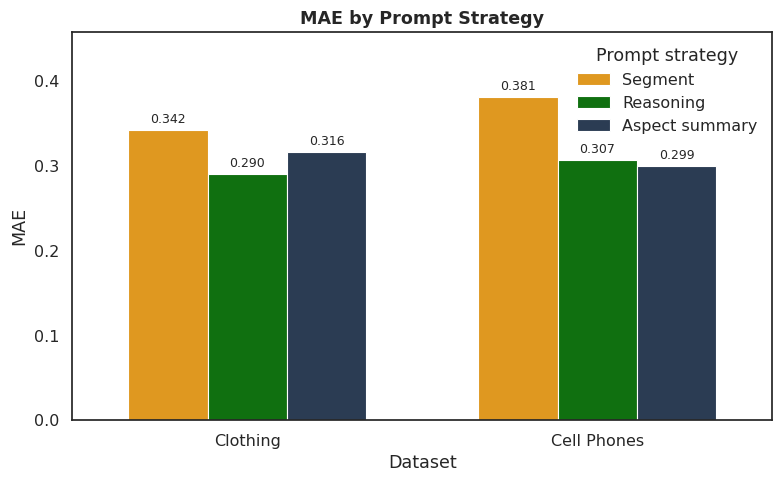

In [14]:
# Prompt별 MAE 비교
prompt_colors = {
    'Segment': '#FFA000',
    'Reasoning': '#008000',
    'Aspect summary': '#243B5A'
}

plt.figure(figsize=(8, 5), facecolor='white')

ax = sns.barplot(
    data=prompt_metrics_df,
    x='dataset',
    y='mae',
    hue='prompt_strategy',
    palette=prompt_colors,
    width=0.68,
    edgecolor='white',
    linewidth=0.8
)

ax.set_title('MAE by Prompt Strategy', fontweight='bold')
ax.set_xlabel('Dataset')
ax.set_ylabel('MAE')
ax.set_ylim(0, prompt_metrics_df['mae'].max() * 1.20)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9)

plt.legend(title='Prompt strategy', frameon=False)
plt.tight_layout()
plt.show()

## 정리

Clothing에서는 Reasoning Prompt가 가장 낮은 MAE를 보였고, Cell Phones에서는 Aspect Summary가 가장 낮았습니다. 출력 길이만으로 성능을 판단하지 않고, 속성 보존과 실제 추천 성능을 함께 해석합니다.